# TRUSTSR Lab 01.4 — Ground-Truth-Independent Uncertainty Policy

**Project:** TRUSTSR — Trust-Aware Causal Semantic Recovery for Long-Horizon Agentic Systems  
**Status:** Synthetic simulation / research prototype  
**Version:** 0.1.0

## Why this lab exists

Lab 01.3 passed its assertions, but its conservative policy used the hidden ground-truth graph to compute the uncertainty boundary. That is a methodological leakage: a deployable policy cannot rely on dependencies that are unavailable to it. This lab corrects that issue.

## Objective

Compare:
1. **Baseline reachability:** Flag descendants reachable from the known poison source in the observed graph.
2. **Observed-graph uncertainty policy:** In addition to baseline descendants, mark each declared missing edge's dependent endpoint and the endpoint's downstream descendants in the *observed graph* as unknown/unverified.

The policy receives the list of missing edges as an explicit signal. It does not automatically detect missing edges. Ground truth is used only for evaluation, never to calculate the policy's output.

## Status labels

- **Confirmed contaminated:** The declared poison source in this synthetic scenario.
- **Potentially contaminated:** Reachable from the poison source in the observed graph.
- **Unknown/unverified:** Included in the uncertainty boundary generated from the missing-edge endpoint and observed-graph descendants, but not already potentially contaminated.
- **Not flagged:** Not in any of the above categories.

## Evaluation

The unchanged synthetic ground-truth graph defines expected affected descendants. We report false negatives, coverage, additional unknown states, and unknown states outside the expected affected set. All outputs are synthetic simulation results—not evidence of real-world effectiveness.

> **Revision note (v0.1.1 package review).** The assertion and prose for the "both poison-source edges missing" scenario previously claimed 5 false negatives; the code yields 0 because the edges are declared. Corrected. No other cell changed.

## 1. Environment setup

In [1]:
%pip -q install networkx pandas matplotlib

In [2]:
import sys
import platform
from datetime import datetime, timezone

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NetworkX:", nx.__version__)
print("Pandas:", pd.__version__)
print("Execution timestamp (UTC):", datetime.now(timezone.utc).isoformat())
print("Evidence type: synthetic simulation only")

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
NetworkX: 3.6.1
Pandas: 3.0.2
Execution timestamp (UTC): 2026-10-11T10:26:25.908898+00:00
Evidence type: synthetic simulation only


## 2. Define the fixed synthetic ground truth

Edge direction is `source → dependent state`. The ground-truth graph is held constant and is used only to define expected affected descendants and score the policies.

In [3]:
states = [
    {"id": "M1", "label": "Trusted project requirement", "kind": "memory", "status": "trusted"},
    {"id": "M2", "label": "Poisoned memory: unsafe instruction", "kind": "memory", "status": "poisoned"},
    {"id": "D1", "label": "Planning decision A", "kind": "decision", "status": "normal"},
    {"id": "D2", "label": "Planning decision B", "kind": "decision", "status": "normal"},
    {"id": "P1", "label": "Execution plan A", "kind": "plan", "status": "normal"},
    {"id": "P2", "label": "Execution plan B", "kind": "plan", "status": "normal"},
    {"id": "A1", "label": "Derived action record", "kind": "action", "status": "normal"},
    {"id": "S1", "label": "Independent status note", "kind": "state", "status": "normal"},
]
dependencies = [
    ("M1", "D1"),
    ("M2", "D1"),
    ("D1", "P1"),
    ("P1", "A1"),
    ("M2", "D2"),
    ("D2", "P2"),
    ("M1", "S1"),
]
POISON_SOURCE = "M2"

G_truth = nx.DiGraph()
for state in states:
    G_truth.add_node(state["id"], **state)
G_truth.add_edges_from(dependencies)
expected_affected = set(nx.descendants(G_truth, POISON_SOURCE))
assert expected_affected == {"D1", "D2", "P1", "P2", "A1"}

print("Ground-truth nodes:", G_truth.number_of_nodes())
print("Ground-truth edges:", G_truth.number_of_edges())
print("Expected affected descendants:", sorted(expected_affected))
display(pd.DataFrame(dependencies, columns=["source", "dependent"]))

Ground-truth nodes: 8
Ground-truth edges: 7
Expected affected descendants: ['A1', 'D1', 'D2', 'P1', 'P2']


  source dependent
0     M1        D1
1     M2        D1
2     D1        P1
3     P1        A1
4     M2        D2
5     D2        P2
6     M1        S1

## 3. Define policies without ground-truth leakage

The conservative policy uses only:
- the observed graph,
- the declared poison source,
- the explicit list of missing edges.

For every missing edge `(u, v)`, it marks `v` and every node reachable from `v` in the observed graph as unknown/unverified, unless already potentially contaminated. It does not query `G_truth` to calculate those states.

This is a conservative heuristic, not a proven optimal policy. The rule only protects against missing edges that are *declared* to it. Undeclared missing edges, or an incomplete state inventory, can still cause misses.

In [4]:
def build_observed_graph(missing_edges):
    observed = G_truth.copy()
    for edge in missing_edges:
        if not observed.has_edge(*edge):
            raise ValueError(f"Invalid or repeated missing edge: {edge}")
        observed.remove_edge(*edge)
    return observed

def baseline_reachability(observed_graph, source):
    return set(nx.descendants(observed_graph, source))

def conservative_observed_graph_policy(observed_graph, source, missing_edges):
    potential = baseline_reachability(observed_graph, source)
    unknown = set()
    for u, v in missing_edges:
        if v not in observed_graph:
            continue
        unknown.add(v)
        unknown.update(nx.descendants(observed_graph, v))
    unknown -= potential
    unknown.discard(source)
    return potential, unknown

def evaluate_scenario(missing_edges, scenario_name):
    observed = build_observed_graph(missing_edges)
    baseline_potential = baseline_reachability(observed, POISON_SOURCE)
    baseline_fn = expected_affected - baseline_potential

    conservative_potential, conservative_unknown = conservative_observed_graph_policy(
        observed, POISON_SOURCE, missing_edges
    )
    conservative_covered = conservative_potential | conservative_unknown
    conservative_fn = expected_affected - conservative_covered
    additional_unknown = conservative_unknown - baseline_potential
    unknown_outside_truth = conservative_unknown - expected_affected
    denominator = len(expected_affected)

    return {
        "scenario": scenario_name,
        "removed_edges": "; ".join(f"{u}->{v}" for u, v in missing_edges) or "(none)",
        "removed_edge_count": len(missing_edges),
        "baseline_false_negatives": len(baseline_fn),
        "baseline_fnr": len(baseline_fn) / denominator if denominator else float("nan"),
        "conservative_false_negatives": len(conservative_fn),
        "conservative_fnr": len(conservative_fn) / denominator if denominator else float("nan"),
        "baseline_coverage": len(baseline_potential & expected_affected) / denominator if denominator else float("nan"),
        "conservative_coverage": len(conservative_covered & expected_affected) / denominator if denominator else float("nan"),
        "additional_unknown_count": len(additional_unknown),
        "unknown_outside_expected_affected_count": len(unknown_outside_truth),
        "baseline_fn_states": sorted(baseline_fn),
        "conservative_fn_states": sorted(conservative_fn),
        "potential_states": sorted(conservative_potential),
        "unknown_states": sorted(conservative_unknown),
        "unknown_outside_expected_affected_states": sorted(unknown_outside_truth),
    }

print("Policy functions defined.")
print("Policy output uses the observed graph only; ground truth is reserved for evaluation.")

Policy functions defined.
Policy output uses the observed graph only; ground truth is reserved for evaluation.


## 4. Evaluate controlled missing-edge scenarios

In [5]:
scenarios = [
    ("Complete graph baseline", []),
    ("Missing D1 -> P1", [("D1", "P1")]),
    ("Missing M2 -> D1", [("M2", "D1")]),
    ("Missing M2 -> D1 and M2 -> D2", [("M2", "D1"), ("M2", "D2")]),
    ("Missing D1 -> P1 and P1 -> A1", [("D1", "P1"), ("P1", "A1")]),
    ("Missing M1 -> S1 (unaffected branch)", [("M1", "S1")]),
]
results = [evaluate_scenario(edges, name) for name, edges in scenarios]
results_df = pd.DataFrame(results)

display(results_df[[
    "scenario", "removed_edge_count",
    "baseline_false_negatives", "baseline_fnr",
    "conservative_false_negatives", "conservative_fnr",
    "additional_unknown_count", "unknown_outside_expected_affected_count",
    "baseline_coverage", "conservative_coverage"
]])

                               scenario  removed_edge_count  baseline_false_negatives  baseline_fnr  conservative_false_negatives  conservative_fnr  additional_unknown_count  \
0               Complete graph baseline                   0                         0           0.0                             0               0.0                         0   
1                      Missing D1 -> P1                   1                         2           0.4                             0               0.0                         2   
2                      Missing M2 -> D1                   1                         3           0.6                             0               0.0                         3   
3         Missing M2 -> D1 and M2 -> D2                   2                         5           1.0                             0               0.0                         5   
4         Missing D1 -> P1 and P1 -> A1                   2                         2           0.4                

## 5. State-level classifications

The source is separately labelled `confirmed_contaminated`. Descendants reachable in the observed graph are `potentially_contaminated`. The conservative policy's uncertainty boundary is `unknown_unverified`. Other nodes are `not_flagged_by_either`.

In [6]:
def state_classification_table(missing_edges, scenario_name):
    observed = build_observed_graph(missing_edges)
    potential, unknown = conservative_observed_graph_policy(observed, POISON_SOURCE, missing_edges)
    rows = []
    for state in states:
        node = state["id"]
        if node == POISON_SOURCE:
            status = "confirmed_contaminated"
        elif node in potential:
            status = "potentially_contaminated"
        elif node in unknown:
            status = "unknown_unverified"
        else:
            status = "not_flagged_by_either"
        rows.append({
            "scenario": scenario_name,
            "state_id": node,
            "state_label": state["label"],
            "synthetic_ground_truth_affected": node in expected_affected,
            "baseline_flagged": node in potential,
            "conservative_unknown": node in unknown,
            "conservative_status": status,
        })
    return pd.DataFrame(rows)

state_tables = pd.concat(
    [state_classification_table(edges, name) for name, edges in scenarios],
    ignore_index=True
)
display(state_tables[state_tables["scenario"] == "Missing D1 -> P1"])

            scenario state_id                          state_label  synthetic_ground_truth_affected  baseline_flagged  conservative_unknown       conservative_status
8   Missing D1 -> P1       M1          Trusted project requirement                            False             False                 False     not_flagged_by_either
9   Missing D1 -> P1       M2  Poisoned memory: unsafe instruction                            False             False                 False    confirmed_contaminated
10  Missing D1 -> P1       D1                  Planning decision A                             True              True                 False  potentially_contaminated
11  Missing D1 -> P1       D2                  Planning decision B                             True              True                 False  potentially_contaminated
12  Missing D1 -> P1       P1                     Execution plan A                             True             False                  True        unknown_unverified
13  

## 6. Plot false-negative rate comparison

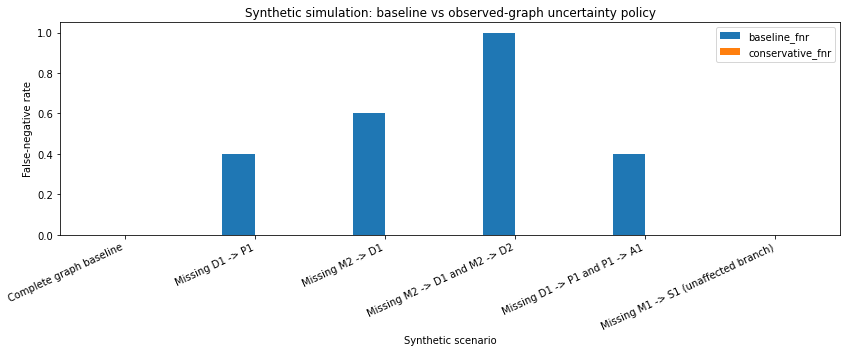

In [7]:
plot_metrics = results_df.set_index("scenario")[["baseline_fnr", "conservative_fnr"]]
ax = plot_metrics.plot(kind="bar", figsize=(12, 5))
ax.set_ylabel("False-negative rate")
ax.set_xlabel("Synthetic scenario")
ax.set_title("Synthetic simulation: baseline vs observed-graph uncertainty policy")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 7. Plot the trade-off

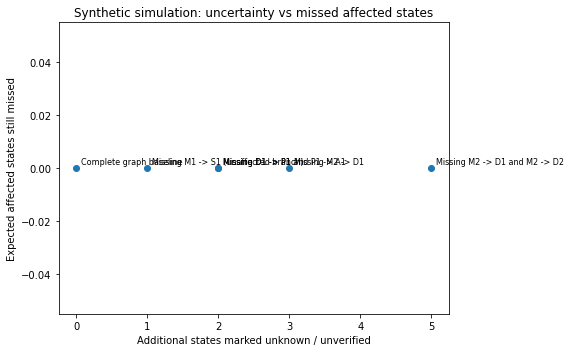

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(results_df["additional_unknown_count"], results_df["conservative_false_negatives"])
for _, row in results_df.iterrows():
    plt.annotate(row["scenario"], (row["additional_unknown_count"], row["conservative_false_negatives"]),
                 xytext=(5, 4), textcoords="offset points", fontsize=8)
plt.xlabel("Additional states marked unknown / unverified")
plt.ylabel("Expected affected states still missed")
plt.title("Synthetic simulation: uncertainty vs missed affected states")
plt.tight_layout()
plt.show()

## 8. Assertions and consistency checks

In [9]:
complete = results_df.loc[results_df["scenario"] == "Complete graph baseline"].iloc[0]
assert complete["baseline_false_negatives"] == 0
assert complete["conservative_false_negatives"] == 0
assert complete["additional_unknown_count"] == 0

case_d1_p1 = results_df.loc[results_df["scenario"] == "Missing D1 -> P1"].iloc[0]
assert case_d1_p1["baseline_false_negatives"] == 2
assert case_d1_p1["conservative_false_negatives"] == 0
assert case_d1_p1["additional_unknown_count"] == 2

case_m2_d1 = results_df.loc[results_df["scenario"] == "Missing M2 -> D1"].iloc[0]
assert case_m2_d1["baseline_false_negatives"] == 3
assert case_m2_d1["conservative_false_negatives"] == 0

case_both_source_edges = results_df.loc[
    results_df["scenario"] == "Missing M2 -> D1 and M2 -> D2"
].iloc[0]
assert case_both_source_edges["baseline_false_negatives"] == 5
assert case_both_source_edges["conservative_false_negatives"] == 0
# Both poison-source edges are missing but *declared*, so the policy marks D1 and D2 (and their
# observed descendants P1, A1, P2) unknown, covering all five affected states. The residual failure
# mode is an UNDECLARED missing edge (blind detection, see Lab 01.7), not this scenario.

case_unaffected = results_df.loc[
    results_df["scenario"] == "Missing M1 -> S1 (unaffected branch)"
].iloc[0]
assert case_unaffected["baseline_false_negatives"] == 0
assert case_unaffected["conservative_false_negatives"] == 0

for col in ["baseline_fnr", "conservative_fnr", "baseline_coverage", "conservative_coverage"]:
    assert results_df[col].between(0, 1).all()

print("PASS: complete graph has zero false negatives and no extra unknown states.")
print("PASS: missing D1 -> P1 marks P1 and A1 unknown under the observed-graph rule.")
print("PASS: missing M2 -> D1 is covered by the declared uncertainty boundary.")
print("PASS: both poison-source edges missing but declared are fully covered by the uncertainty boundary.")
print("PASS: unaffected-branch removal creates no poison-descendant false negatives.")
print("PASS: rate metrics are between 0 and 1.")
print("All Lab 01.4 assertions passed.")

PASS: complete graph has zero false negatives and no extra unknown states.
PASS: missing D1 -> P1 marks P1 and A1 unknown under the observed-graph rule.
PASS: missing M2 -> D1 is covered by the declared uncertainty boundary.
PASS: both poison-source edges missing but declared are fully covered by the uncertainty boundary.
PASS: unaffected-branch removal creates no poison-descendant false negatives.
PASS: rate metrics are between 0 and 1.
All Lab 01.4 assertions passed.


## 9. Export CSV artifacts

In [10]:
results_df.to_csv("trustsr_lab01_4_policy_comparison.csv", index=False)
state_tables.to_csv("trustsr_lab01_4_state_classifications.csv", index=False)

print("Generated files:")
print("- trustsr_lab01_4_policy_comparison.csv")
print("- trustsr_lab01_4_state_classifications.csv")

Generated files:
- trustsr_lab01_4_policy_comparison.csv
- trustsr_lab01_4_state_classifications.csv


## 10. Interpretation and limitations

### What changed from Lab 01.3

The policy no longer uses the hidden ground-truth graph to determine which states are downstream of a missing edge. It now uses only the observed graph and the explicitly supplied missing-edge list.

### Expected interpretation

- For a missing internal edge such as `D1 → P1`, the policy can mark the endpoint `P1` and observed descendants such as `A1` as unknown/unverified.
- If both edges from the poison source `M2` are missing **and declared**, the policy marks `D1`, `D2` and their observed descendants unknown, so all five affected states are covered (at the cost of review work). The earlier text claiming this case is missed was inconsistent with the code and was corrected in v0.1.1. If those edges were *not declared*, the policy would receive no signal and would miss them; that blind case is studied in Lab 01.7.
- Conservative unknown marking may increase the number of states that require review or quarantine. That cost must be measured, not ignored.

### What is not established

- Real-world effectiveness or false-negative rates.
- Automatic discovery of missing edges.
- Recovery, containment, or trusted checkpoint restoration.
- Formal soundness/completeness guarantees.
- Support for numerical claims in the TRUSTSR monograph.

**Reporting rule:** All results are synthetic simulation outputs. This lab removes one source of evaluation leakage but does not turn the prototype into a validated real-world system.